# B1 / B5 · Plan model, policy evaluator and baselines (live session)

PLAN §7 B1 and B5. Stream B owns it. Builds the weekly planning problem and the yardsticks the GA will be measured against:

1. **Load**: member scores, the rules' allowed offers, the live offer catalogue, staff roster and limits.
2. **Instance**: one row per option (member, offer, channel) with cost, staff minutes and estimated uplift.
3. **Objective**: value = uplift × monthly fee × H − cost, with H = 6 months (decision #2).
4. **Feasibility**: budget, staff minutes, trainer minutes, stock, one contact per member, allowed options only.
5. **Policy evaluator**: grades any plan with the scenario's hidden truth (`true_uplift`, `true_churn`).
6. **Baselines**: contact-all and risk-top-k with the playbook's top offer (decision #3), greedy-uplift.
7. **First E4 numbers.**

Candidates are the rules' `allowed` offers only: playbook proposals that no guardrail blocked (HANDOFFS #6).
Estimated uplift comes from the CBR (`anchorai.cbr`, PLAN drift item 8); `b_cbr` compares it with A's T-learner. `true_uplift` and `true_churn` are used
**only** in the evaluator, never to choose a plan.

The logic lives in `anchorai.optimisation` (`model`, `evaluate`, `baselines`); this notebook imports it. Nothing is written to the app DB. It reads the built data
(`uv run anchorai setup`).

## 1. Load

Reads the live catalogue, roster and limits from the app DB (`catalog.py`), not `offers.parquet`, so admin edits count.
Rules run on every member with the active rule version; `drop_inactive` removes offers an admin switched off.

**Look for:** 4,000 members; about 1,050 with an allowed offer (the demo week's logged contacts block some); budget $1,500 and 2,160 staff minutes;
only `staff1` has the `trainer` skill.

In [1]:
from pathlib import Path

import pandas as pd
from anchorai.config import get_settings
from anchorai.db.session import get_engine
from anchorai.optimisation.model import load_instance
from sqlmodel import Session

SEED = get_settings().anchorai_seed
FIG, RES = Path("figures"), Path("results")

session = Session(get_engine())
instance = load_instance(session)
options, constraints, limits = instance.options, instance.constraints, instance.limits()

print(
    f"{len(instance.outcomes)} members | {sum(bool(o.allowed) for o in instance.outcomes.values())} "
    "members with an allowed offer"
)
print(constraints)
display(pd.DataFrame([s.model_dump() for s in instance.staff]).set_index("username"))
pd.DataFrame([o.model_dump() for o in instance.offers]).set_index("offer_id")

4000 members | 1045 members with an allowed offer
default_budget=1500.0 default_staff_minutes=2160 max_contacts_per_member_per_30d=1 max_offers_per_member_per_90d=2


,weekly_hours,skills,user_id,full_name
username,,,,
staff1,20.0,"[trainer, calls]",3,Sam Staff
staff2,16.0,[calls],4,Jordan Staff


,name,cost,staff_minutes,inventory,channels,eligibility,required_skill,active
offer_id,,,,,,,,
checkin_message,Personal check-in message,0.0,5,NaN,"[sms, email, call]",Any active member,,True
class_pass,Bring-a-friend class pass,15.0,10,100.0,"[sms, email, call]",Any active member,,True
discount_1m,One month at 20% off,12.0,15,NaN,"[email, call]",Month-to-month members only,,True
free_pt_session,Free personal training session,40.0,60,40.0,"[call, in_person]",Members without PT in the last 90 days,trainer,True


## 2. Instance

One row per **option**: a member, one of their allowed offers and the channel the playbook chose. `rank` 0 is the
playbook's top offer. `est_uplift` is the CBR estimate; `value` = est_uplift × monthly fee × H − cost.
"No contact" has no row: it is the default, worth $0.

**Look for:** about 2,025 options for 1,045 members, at most 4 per member. Which offers the estimates think are worth
their cost (`worth_it` = share of options with value > 0).

In [2]:
print(
    f"{len(options)} options for {options['member_id'].nunique()} members "
    f"({options.groupby('member_id').size().max()} at most per member)"
)
options.groupby("offer_id").agg(
    options=("member_id", "size"),
    est_uplift=("est_uplift", "mean"),
    value=("value", "mean"),
    worth_it=("value", lambda v: (v > 0).mean()),
).round(3)

2025 options for 1045 members (4 at most per member)


,options,est_uplift,value,worth_it
offer_id,,,,
checkin_message,626,0.008,3.196,1.000
class_pass,168,0.042,2.183,0.780
discount_1m,587,0.057,12.518,0.905
free_pt_session,644,0.149,21.945,0.907


## 3. Objective

What the planner maximises: the dollar value it *believes* a plan has. The GA will call this as its fitness.

**Look for:** giving every member their top offer would cost far more than the $1,500 budget and the 2,160 staff
minutes. That gap is why choosing matters.

In [3]:
from anchorai.optimisation.model import plan_value

top = options[options["rank"] == 0]
print(
    f"if every member got their playbook top offer: {len(top)} contacts, "
    f"${top['cost'].sum():,.0f}, {top['staff_minutes'].sum():,} staff minutes, value ${plan_value(top):,.0f}"
)

if every member got their playbook top offer: 1045 contacts, $24,655, 38,480 staff minutes, value $14,456


## 4. Feasibility

A plan is feasible only if it breaks no limit: allowed options only, one contact per member, budget, staff minutes,
trainer minutes (free PT needs a trainer, and only trainers' hours count) and stock. Contact fatigue and offer caps are
already enforced by guardrails G01 and G02, so they never reach the options table.

**Look for:** the "all top offers" plan breaks budget, staff minutes, trainer minutes and PT stock; the empty plan
breaks nothing (`{}`).

In [4]:
from anchorai.optimisation.model import violations

print(limits)
print("all top offers:", violations(top, options, limits))
print("empty plan:", violations(options.iloc[:0], options, limits))

Limits(budget=1500.0, staff_minutes=2160, trainer_minutes=1200, stock={'class_pass': 100, 'free_pt_session': 40})
all top offers: {'budget ($)': 23155.0, 'staff minutes': 36320.0, 'trainer minutes': 34680.0, 'free_pt_session stock': 558.0}
empty plan: {}


## 5. Policy evaluator

Grades any plan with the scenario's hidden truth: `true_churn.event_churn` for members left alone and
`true_uplift` for the contacted ones (HANDOFFS #26). **Only used to grade, never to choose.**
`estimated_extra` is what the plan's own estimates claimed, so the two can be compared.

**Look for:** about 2,660 of 4,000 members stay with no contact. `extra_retained` (truth) vs `estimated_extra`
(T-learner): how far off the estimates are.

In [5]:
from anchorai.optimisation.evaluate import evaluate, load_truth

truth = load_truth()
print(
    f"no contact at all: {truth.stay_if_left_alone.sum():,.0f} of {len(truth.stay_if_left_alone)} "
    "members expected to stay next month"
)
pd.Series(evaluate(top, truth)).round(2)

no contact at all: 2,661 of 4000 members expected to stay next month


contacts             1045.00
spend               24655.00
staff_minutes       38480.00
members_retained     2812.60
extra_retained        151.35
estimated_extra        94.31
per_1000_dollars        6.14
per_staff_hour          0.24
dtype: float64

## 6. Baselines

All three fill the plan the same way (`fill`: walk the options in order, take each one that still fits every limit),
so they differ only in the **order**:
- **contact-all:** playbook top offer, members in random order (decision #3)
- **risk-top-k:** playbook top offer, highest churn risk first (decision #3)
- **greedy-uplift:** any allowed option with value > 0, best value per share of budget and staff time first

**Look for:** `violations` = 0 for all three. Which limit runs out first (compare `spend` with $1,500 and
`staff_minutes` with 2,160). How the three compare on `extra_retained`.

In [6]:
from anchorai.optimisation.baselines import POLICIES

pd.DataFrame(
    {
        name: {
            **evaluate(p := f(options, limits, SEED), truth),
            "violations": len(violations(p, options, limits)),
        }
        for name, f in POLICIES.items()
    }
).T.round(2)

,contacts,spend,staff_minutes,members_retained,extra_retained,estimated_extra,per_1000_dollars,per_staff_hour,violations
contact-all,182.0,1124.0,2160.0,2671.31,10.06,5.20,8.95,0.28,0.0
risk-top-k,156.0,1280.0,2160.0,2674.96,13.70,6.20,10.70,0.38,0.0
greedy-uplift,360.0,432.0,2160.0,2682.22,20.96,5.63,48.53,0.58,0.0


## 7. First E4 numbers

E4 varies **both** limits: five budgets at three staff levels (today's roster of 36 h, double it, and C's E6 setting of
120 h), five seeds each (only contact-all is random). With today's roster staff time runs out before money, so a
budget axis alone would be flat. Saved to `results/b5_e4_baselines.csv` and `figures/b5_e4_baselines.png`.

**Look for:** 0 violations (the assert). At 2,160 minutes the lines are flat: more budget buys nothing. With more staff
the lines rise until time or money runs out. The gap between greedy-uplift and the other two at each setting is what
the GA must beat later. `per_staff_hour` is the fairer efficiency measure when spend is near $0.

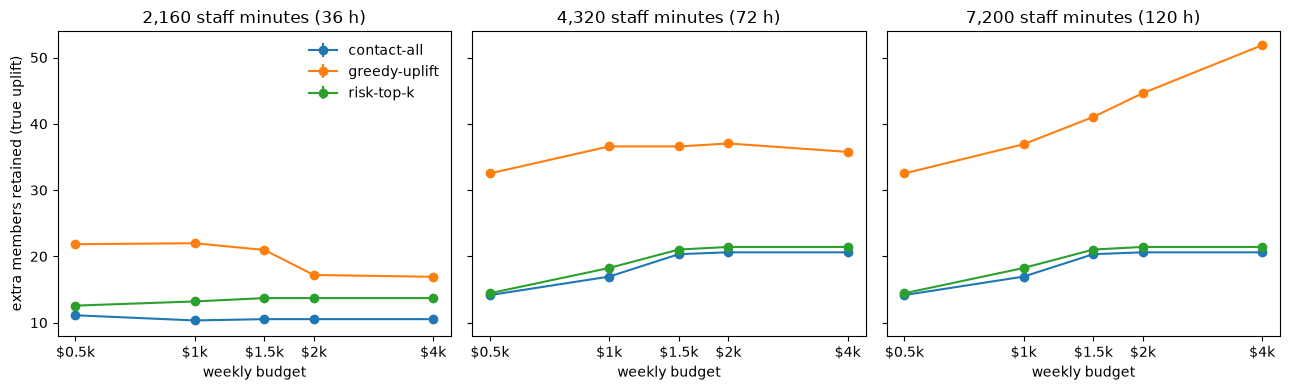

contacts   spend  staff_minutes  \
policy        staff_limit budget                                    
contact-all   2160        500        300.2   494.8         2160.0   
                          1000       192.2   992.6         2160.0   
                          1500       185.8  1056.2         2160.0   
                          2000       185.8  1056.2         2160.0   
                          4000       185.8  1056.2         2160.0   
              4320        500        407.4   494.8         2696.0   
                          1000       428.0   992.6         3339.0   
                          1500       464.0  1493.0         3765.0   
                          2000       467.0  1535.0         3800.0   
                          4000       467.0  1535.0         3800.0   
              7200        500        407.4   494.8         2696.0   
                          1000       428.0   992.6         3339.0   
                          1500       464.0  1493.0         3765.0   
                          2000       467.0  1535.0         3800.0   
                          4000       467.0  1535.0         3800.0   
greedy-uplift 2160        500        432.0     0.0         2160.0   
                          1000       420.0    72.0         2160.0   
                          1500       360.0   432.0         2160.0   
                          2000       192.0  1440.0         2160.0   
                          4000       144.0  1728.0         2160.0   
              4320        500        667.0   492.0         3745.0   
                          1000       705.0   948.0         4315.0   
                          1500       705.0   948.0         4315.0   
                          2000       686.0  1068.0         4320.0   
                          4000       524.0  2040.0         4320.0   
              7200        500        667.0   492.0         3745.0   
                          1000       709.0   996.0         4375.0   
                          1500       751.0  1500.0         5005.0   
                          2000       790.0  1996.0         5635.0   
                          4000       858.0  3148.0         7195.0   
risk-top-k    2160        500        298.0   492.0         2160.0   
                          1000       182.0   998.0         2160.0   
                          1500       156.0  1280.0         2160.0   
                          2000       156.0  1280.0         2160.0   
                          4000       156.0  1280.0         2160.0   
              4320        500        407.0   492.0         2705.0   
                          1000       430.0   998.0         3400.0   
                          1500       464.0  1490.0         3770.0   
                          2000       467.0  1535.0         3800.0   
                          4000       467.0  1535.0         3800.0   
              7200        500        407.0   492.0         2705.0   
                          1000       430.0   998.0         3400.0   
                          1500       464.0  1490.0         3770.0   
                          2000       467.0  1535.0         3800.0   
                          4000       467.0  1535.0         3800.0   

                                  extra_retained  per_staff_hour  extra_sd  
policy        staff_limit budget                                            
contact-all   2160        500              11.11            0.31      0.24  
                          1000             10.33            0.29      0.27  
                          1500             10.53            0.29      0.25  
                          2000             10.53            0.29      0.25  
                          4000             10.53            0.29      0.25  
              4320        500              14.16            0.32      0.15  
                          1000             16.95            0.30      0.30  
                          1500             20.33            0.32      0.34  
                    

In [7]:
import matplotlib.pyplot as plt

BUDGETS = [500, 1000, 1500, 2000, 4000]
M = limits.staff_minutes
# today's roster (36 h), double it, C's E6 setting (120 h)
STAFF_LEVELS = [M, 2 * M, 7200]
SEEDS = range(5)

rows = []
for staff_minutes in STAFF_LEVELS:
    for budget in BUDGETS:
        for seed in SEEDS:
            for name, f in POLICIES.items():
                week = instance.limits(budget, staff_minutes)
                plan = f(options, week, seed)
                rows.append(
                    {
                        "policy": name,
                        "staff_limit": staff_minutes,
                        "budget": budget,
                        "seed": seed,
                        **evaluate(plan, truth),
                        "violations": len(violations(plan, options, week)),
                    }
                )
runs = pd.DataFrame(rows)
assert runs["violations"].eq(0).all(), "a baseline produced an infeasible plan"

FIG.mkdir(exist_ok=True)
RES.mkdir(exist_ok=True)
keys = ["policy", "staff_limit", "budget"]
summary = runs.groupby(keys)[
    ["contacts", "spend", "staff_minutes", "extra_retained", "per_staff_hour"]
].mean()
summary["extra_sd"] = runs.groupby(keys)["extra_retained"].std()
summary.round(2).to_csv(RES / "b5_e4_baselines.csv")

fig, axes = plt.subplots(1, len(STAFF_LEVELS), figsize=(13, 4), sharey=True)
for ax, staff_minutes in zip(axes, STAFF_LEVELS):
    level = summary.xs(staff_minutes, level="staff_limit").reset_index()
    for name, g in level.groupby("policy"):
        ax.errorbar(
            g["budget"],
            g["extra_retained"],
            yerr=g["extra_sd"].fillna(0),
            marker="o",
            label=name,
        )
    ax.set_xscale("log")
    ax.minorticks_off()
    ax.set_xticks(BUDGETS, [f"${b / 1000:g}k" for b in BUDGETS])
    ax.set_xlabel("weekly budget")
    ax.set_title(f"{staff_minutes:,} staff minutes ({staff_minutes // 60} h)")
axes[0].set_ylabel("extra members retained (true uplift)")
axes[0].legend(frameon=False)
fig.tight_layout()
fig.savefig(FIG / "b5_e4_baselines.png")
plt.show()
summary.round(2)